# Predicting Medical Insurance Costs: from EDA to an Explainable Model

**Goal:** understand what drives individual medical insurance charges and build a model that predicts them, then explain *why* it predicts what it does.

**Dataset:** `insurance.csv` (1,338 rows): `age, sex, bmi, children, smoker, region, charges`.

**Outline**
1. Data check and cleaning
2. Exploratory analysis (the smoker x BMI story)
3. Feature engineering
4. Model comparison with cross-validation
5. Tuning the best model
6. Error analysis
7. Explainability
8. Fairness notes and limitations
9. Save the model for the web app

In [22]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 1. Data check and cleaning

In [25]:
df = pd.read_csv("../data/raw/insurance.csv")
print(df.shape)
display(df.head())
print(df.isna().sum().to_string())
print("Duplicate rows:", df.duplicated().sum())

(1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
Duplicate rows: 1


In [26]:
df = df.drop_duplicates().reset_index(drop=True)
print("After dropping duplicates:", df.shape)
display(df.describe().T)

After dropping duplicates: (1337, 7)


,count,mean,std,min,25%,50%,75%,max
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801


## 2. Exploratory analysis

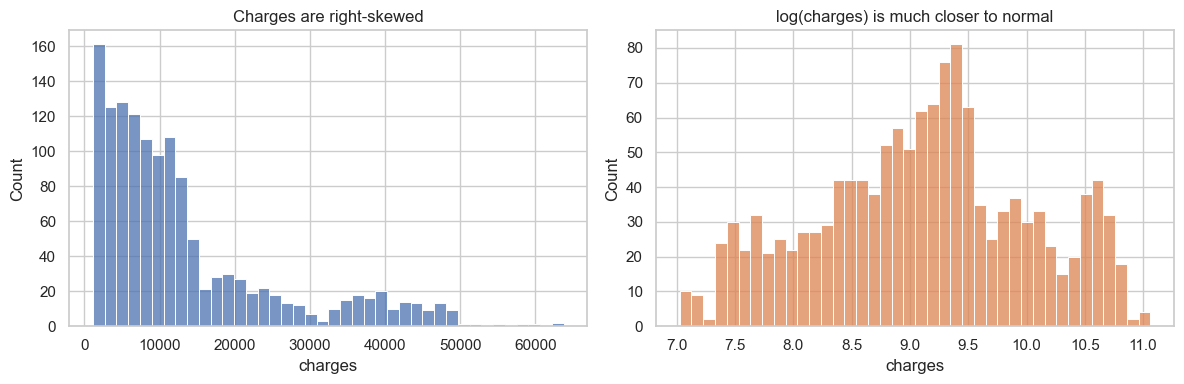

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], bins=40, ax=ax[0]); ax[0].set_title("Charges are right-skewed")
sns.histplot(np.log1p(df["charges"]), bins=40, ax=ax[1], color="C1"); ax[1].set_title("log(charges) is much closer to normal")
plt.tight_layout(); plt.show()

The target is heavily right-skewed, so a log transform is worth testing. We will test it inside the pipeline rather than assume it helps, and judge it on dollar-scale errors.

,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


Smokers pay about 3.8x more on average.


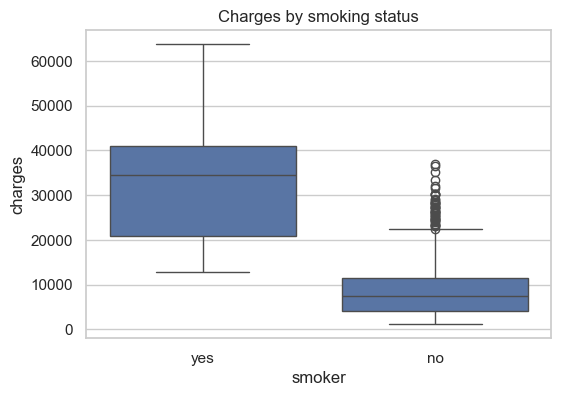

In [28]:
summary = df.groupby("smoker")["charges"].agg(["count", "mean", "median"]).round(0)
display(summary)
ratio = summary.loc["yes", "mean"] / summary.loc["no", "mean"]
print(f"Smokers pay about {ratio:.1f}x more on average.")

plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Charges by smoking status"); plt.show()

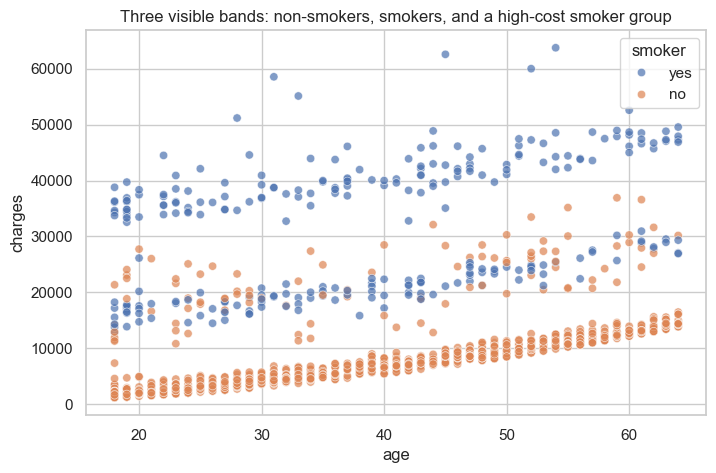

In [29]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7)
plt.title("Three visible bands: non-smokers, smokers, and a high-cost smoker group"); plt.show()

Age drives cost upward in a roughly linear way, but the bands show that **smoking changes the level**, and the top band hints at an interaction with something else. Let us check BMI.

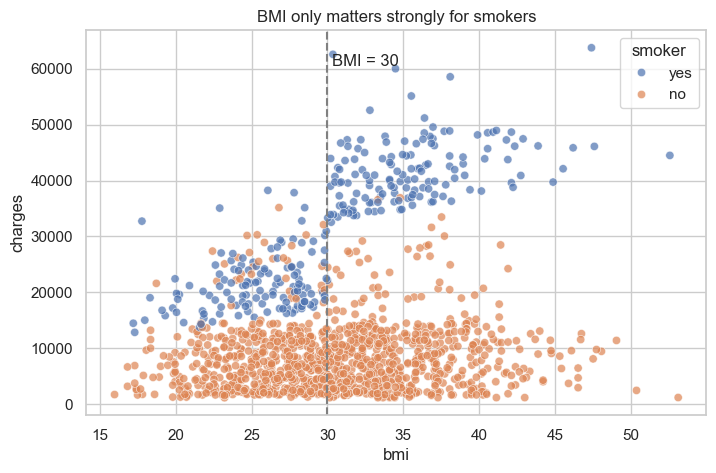

obese,BMI < 30,BMI >= 30
smoker,,
no,7977.0,8856.0
yes,21363.0,41558.0


In [30]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7)
plt.axvline(30, color="grey", ls="--"); plt.text(30.3, df["charges"].max()*0.95, "BMI = 30")
plt.title("BMI only matters strongly for smokers"); plt.show()

df["obese"] = (df["bmi"] >= 30).astype(int)
display(df.pivot_table(values="charges", index="smoker", columns="obese", aggfunc="mean").round(0)
          .rename(columns={0: "BMI < 30", 1: "BMI >= 30"}))

**Key insight:** for non-smokers, BMI barely changes the average cost. For smokers, having BMI >= 30 pushes costs dramatically higher. A purely additive linear model cannot capture this, so we either engineer an interaction feature or use a model that learns interactions on its own. Below we test both.

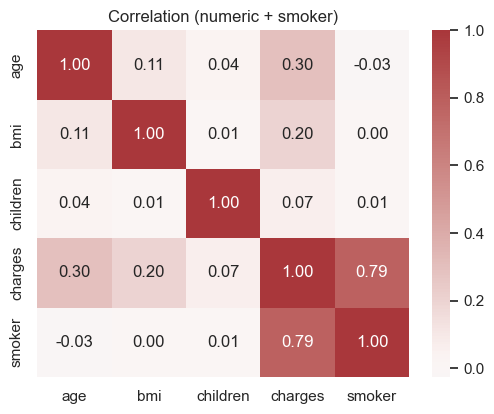

In [31]:
num = df[["age", "bmi", "children", "charges"]].copy()
num["smoker"] = (df["smoker"] == "yes").astype(int)
plt.figure(figsize=(6, 4.5))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation (numeric + smoker)"); plt.show()

## 3. Feature engineering

In [32]:
def add_features(d):
    d = d.copy()
    d["obese"] = (d["bmi"] >= 30).astype(int)
    d["smoker_obese"] = ((d["smoker"] == "yes") & (d["bmi"] >= 30)).astype(int)
    return d

df = add_features(df.drop(columns=["obese"]))
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=df["smoker"])
print(X_train.shape, X_test.shape)

cat_cols = ["sex", "smoker", "region"]
num_cols = ["age", "bmi", "children", "obese", "smoker_obese"]

base_num = ["age", "bmi", "children"]

def make_pipe(model, use_log=True, nums=None):
    nums = num_cols if nums is None else nums
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first"), cat_cols),
        ("num", "passthrough", nums),
    ])
    pipe = Pipeline([("pre", pre), ("model", model)])
    if use_log:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

(1069, 8) (268, 8)


## 4. Model comparison (5-fold cross-validation on the training set)

In [33]:
models = {
    "Linear (no engineered features)": make_pipe(LinearRegression(), use_log=False, nums=base_num),
    "Linear (raw target)":      make_pipe(LinearRegression(), use_log=False),
    "Linear (log target)":      make_pipe(LinearRegression()),
    "Ridge (log target)":       make_pipe(Ridge(alpha=1.0)),
    "Random Forest":            make_pipe(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE), use_log=False),
    "Gradient Boosting":        make_pipe(GradientBoostingRegressor(random_state=RANDOM_STATE), use_log=False),
}
cv = KFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    s = cross_validate(m, X_train, y_train, cv=cv,
                       scoring=["r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"])
    rows.append({"model": name,
                 "R2": s["test_r2"].mean(),
                 "MAE": -s["test_neg_mean_absolute_error"].mean(),
                 "RMSE": -s["test_neg_root_mean_squared_error"].mean()})
results = pd.DataFrame(rows).sort_values("R2", ascending=False).round(3)
display(results)

,model,R2,MAE,RMSE
1,Linear (raw target),0.842,2694.463,4715.179
5,Gradient Boosting,0.835,2764.582,4812.785
4,Random Forest,0.835,2766.669,4813.089
0,Linear (no engineered features),0.722,4392.589,6297.118
3,Ridge (log target),0.479,4229.915,8679.279
2,Linear (log target),0.469,4256.123,8762.467


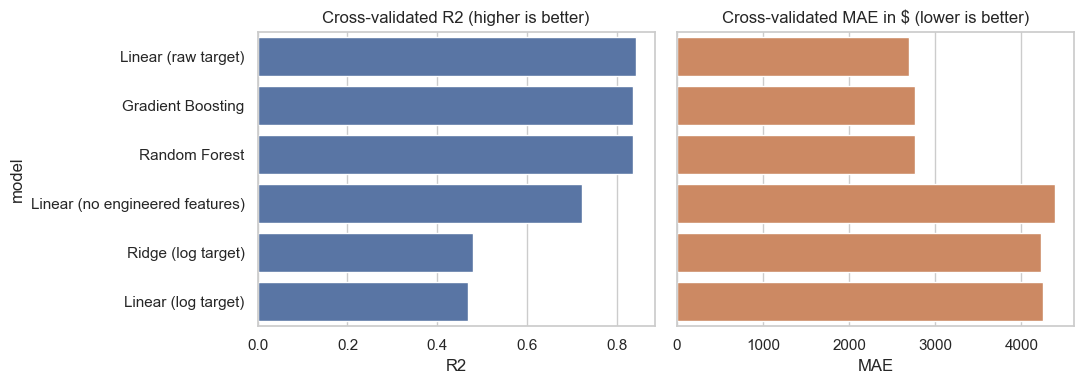

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=results, y="model", x="R2", ax=ax[0], color="C0"); ax[0].set_title("Cross-validated R2 (higher is better)")
sns.barplot(data=results, y="model", x="MAE", ax=ax[1], color="C1"); ax[1].set_title("Cross-validated MAE in $ (lower is better)")
ax[1].set_ylabel(""); ax[1].set_yticklabels([])
plt.tight_layout(); plt.show()

**What the table shows (read it before trusting any claim):**
- Adding the `smoker_obese` interaction feature lifts the plain linear model a lot. Compare "Linear (no engineered features)" with "Linear (raw target)". This is the EDA insight paying off.
- Once that feature exists, an untuned linear model is competitive with untuned tree ensembles, so a fancier model is not automatically better.
- The log-target versions score *worse* in dollars. A model that is accurate in log space can still make large dollar errors on expensive cases after converting back, so we keep the raw target.

## 5. Tuning the best model

In [35]:
gb = GradientBoostingRegressor(random_state=RANDOM_STATE)
pipe = make_pipe(gb, use_log=False)
grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [2, 3, 4],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
}
search = GridSearchCV(pipe, grid, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Tuned Gradient Boosting CV RMSE:", round(-search.best_score_, 0))
print("Linear (raw target) CV RMSE:      ", float(results.loc[results.model == "Linear (raw target)", "RMSE"].iloc[0]))
best = search.best_estimator_

Best params: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}
Tuned Gradient Boosting CV RMSE: 4702.0
Linear (raw target) CV RMSE:       4715.179


In [36]:
pred = best.predict(X_test)
final = {"R2": r2_score(y_test, pred),
         "MAE": mean_absolute_error(y_test, pred),
         "RMSE": np.sqrt(mean_squared_error(y_test, pred))}
print({k: round(float(v), 3) for k, v in final.items()})
print("Note: one 268-row test split is a noisy estimate; trust the cross-validated numbers for comparing models.")

{'R2': 0.918, 'MAE': 2169.573, 'RMSE': 3428.603}
Note: one 268-row test split is a noisy estimate; trust the cross-validated numbers for comparing models.


**Honest takeaway:** tuned boosting and the linear model with the interaction feature end up almost tied in cross-validation (RMSE about 4,700 for both). The biggest gain came from the *insight* (smoker x obesity), not from model complexity. In the README, say this plainly; it shows good judgment.

## 6. Error analysis

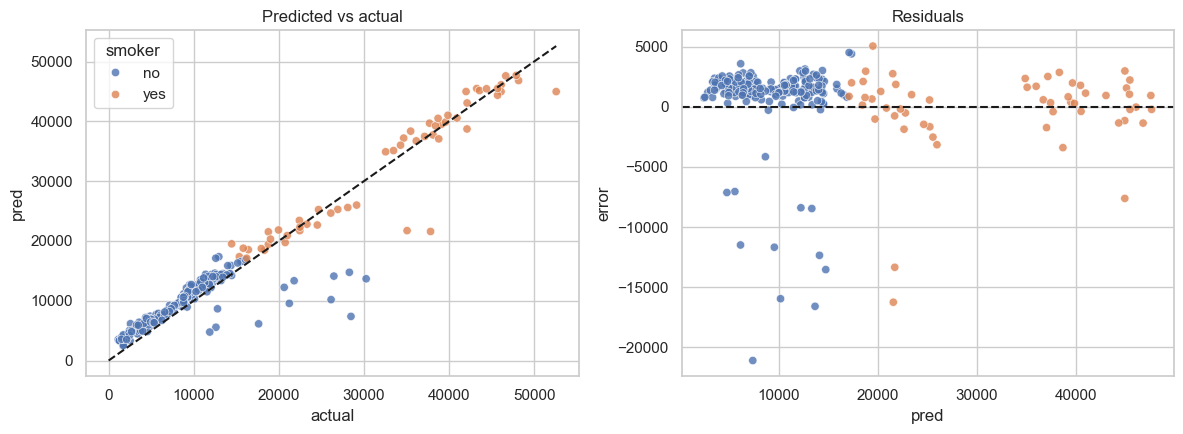

,MAE,bias
smoker,,
no,2209.0,910.0
yes,2015.0,-185.0


,actual,pred,error,smoker,age,bmi
805,28477.0,7378.0,-21099.0,no,40,41.0
115,30260.0,13670.0,-16590.0,no,60,29.0
1302,37830.0,21582.0,-16248.0,yes,43,28.0
875,26140.0,10182.0,-15958.0,no,49,27.0
443,28288.0,14753.0,-13534.0,no,59,37.0
916,35069.0,21727.0,-13342.0,yes,45,23.0
963,26467.0,14119.0,-12348.0,no,52,37.0
1002,21232.0,9557.0,-11675.0,no,48,30.0


In [37]:
res = pd.DataFrame({"actual": y_test.values, "pred": pred}, index=y_test.index)
res["error"] = res["pred"] - res["actual"]
res = res.join(X_test[["smoker", "age", "bmi"]])

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=res, x="actual", y="pred", hue="smoker", ax=ax[0], alpha=0.8)
lim = [0, res[["actual", "pred"]].max().max()]
ax[0].plot(lim, lim, "k--"); ax[0].set_title("Predicted vs actual")
sns.scatterplot(data=res, x="pred", y="error", hue="smoker", ax=ax[1], alpha=0.8, legend=False)
ax[1].axhline(0, color="k", ls="--"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

display(res.groupby("smoker")["error"].agg(MAE=lambda e: e.abs().mean(), bias="mean").round(0))
display(res.reindex(res["error"].abs().sort_values(ascending=False).index).head(8).round(0))

Look at where the model is wrong: the largest errors usually come from people whose cost is driven by something this dataset does not capture (a specific illness or surgery). That is a real limitation of the data, not just the model.

## 7. Explainability

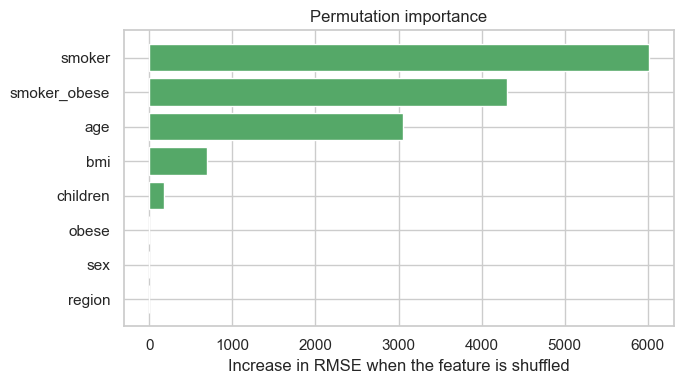

In [38]:
perm = permutation_importance(best, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring="neg_root_mean_squared_error")
imp = (pd.DataFrame({"feature": X_test.columns, "importance": perm.importances_mean})
         .sort_values("importance"))
plt.figure(figsize=(7, 4))
plt.barh(imp["feature"], imp["importance"], color="C2")
plt.xlabel("Increase in RMSE when the feature is shuffled"); plt.title("Permutation importance")
plt.tight_layout(); plt.show()

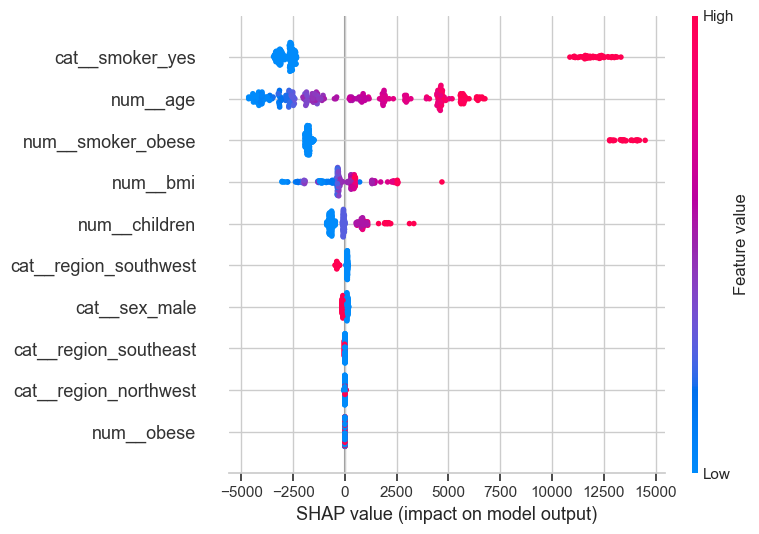

In [39]:
# Optional: SHAP gives per-prediction explanations. Install with: pip install shap
try:
    import shap
    inner = best.regressor_ if hasattr(best, "regressor_") else best
    Xt = inner.named_steps["pre"].transform(X_test)
    names = inner.named_steps["pre"].get_feature_names_out()
    explainer = shap.TreeExplainer(inner.named_steps["model"])
    sv = explainer.shap_values(Xt)
    shap.summary_plot(sv, Xt, feature_names=names)
except ImportError:
    print("shap is not installed; skipping. Run `pip install shap` to enable this cell.")

## 8. Fairness notes and limitations

- **Sensitive attributes:** `sex` and `region` are in the data, but using them to set individual prices raises fairness and legal questions in many jurisdictions. A production system would need to justify or remove them. You can test this by retraining without them and comparing the metrics.
- **Small and old data:** only ~1,300 rows from one (US) setting, and no clinical history. Costs are driven mostly by things we cannot see.
- **Not a pricing tool:** this is a learning project. Predictions are estimates with wide error, especially for rare high-cost cases.

In [40]:
# Does removing sex & region hurt?
cols_fair_cat = ["smoker"]
pre = ColumnTransformer([("cat", OneHotEncoder(drop="first"), cols_fair_cat),
                         ("num", "passthrough", num_cols)])
fair = Pipeline([("pre", pre), ("model", GradientBoostingRegressor(
        random_state=RANDOM_STATE, **{k.replace("model__", ""): v for k, v in search.best_params_.items()}))])
fair.fit(X_train, y_train)
p2 = fair.predict(X_test)
print("Without sex & region -> R2:", round(r2_score(y_test, p2), 3), " MAE:", round(mean_absolute_error(y_test, p2), 0))
print("With    sex & region -> R2:", round(final["R2"], 3), " MAE:", round(final["MAE"], 0))

Without sex & region -> R2: 0.92  MAE: 2133.0
With    sex & region -> R2: 0.918  MAE: 2170.0


## 9. Save the model for the web app

In [41]:
best.fit(X, y)   # refit on all data for deployment
joblib.dump(best, "model.joblib")
print("Saved model.joblib")

Saved model.joblib
